The goal of this notebook is to ...

In [1]:
# No need to restart notebook when editing custom packages
%load_ext autoreload
%autoreload 2

In [ ]:
# Built-in Imports
import matplotlib.pyplot as plt
from pathlib import Path

# Dependancy Imports
import toml
import numpy as np
import scanpy as sc
from adjustText import adjust_text

# Custom Imports
import hm3d_utils
from project_utils import FileTracker, in_container_check

# General Constants
MM = 1/25.4

# Project-wide Constants
CONFIG = toml.load(open('../config.toml', 'r'))
DATADIR = Path(CONFIG['DATADIR'])
RCPARAMS = CONFIG['MPLSTYLE']

# Notebook-specific Constants
YZ = 30

tracker = FileTracker(log_file=DATADIR/'tracked_files.toml')

sc.set_figure_params(frameon=False, dpi=120)

in_container_check(warn_only=False)

### Let's ...

In [3]:
x = 10
x * YZ

300

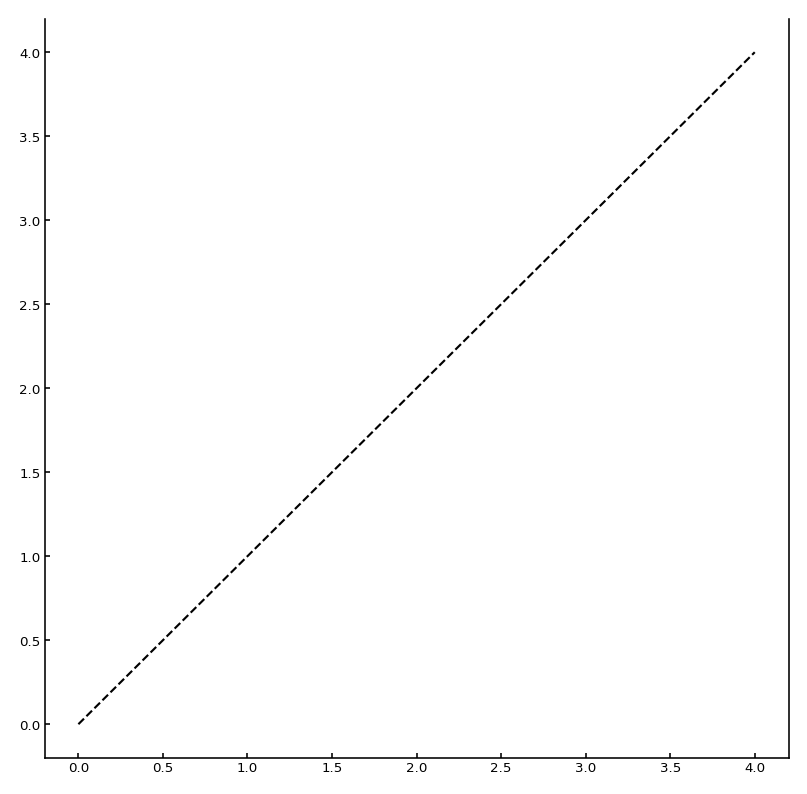

In [ ]:
# RCPARAMS are global adjusted defaults for matplotlib but locally rc can overide behaviours e.g. right spine is wanted
with plt.rc_context(
    fname=RCPARAMS, 
    rc={'axes.spines.right': True}
    ):
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))

    cmap = plt.get_cmap('viridis').reversed()
    
    ax.plot(
        [0, 1, 2, 3, 4],
        [0, 1, 2, 3, 4],
        linestyle='dashed',
        color='black'
    )

    hm3d_utils.pl.zoom_embedding()

    with tracker.register(DATADIR/"test_plot.png") as tf:
        tf.set_description('A matplotlib figure that tests the file tracker is working as intended.')
        fig.savefig(tf.filepath)

    plt.show()
    plt.close(fig)